<div align="center">

<h1> <b> CONSTANTE DE BOLTZMANN A PARTIR DE LA ECUACIÓN DE SHOCKLEY DEL DIODO </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Vergara Restrepo <br>
Santiago Ramírez Gaviria</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>

---


# Determinación de la constante de Boltzmann con la ecuación de diodo de Shockley

**Física Experimental IV**

## Objetivo general

Determinar el valor de la constante de Boltzmann a partir de mediciones de voltaje y corriente en un diodo semiconductor a temperatura conocida.

## Objetivos específicos

- Registrar curvas de corriente en función del voltaje para un diodo operado con dos resistencias de referencia distintas.
- Ajustar los datos experimentales a la ecuación de Shockley mediante regresión no lineal.
- A partir de los parámetros del ajuste, obtener el producto $n\,k_B$ y, de él, el factor de idealidad del diodo y un valor experimental de la constante de Boltzmann comparable con el valor de referencia de CODATA.

## Marco teórico

La ecuación de Shockley describe la corriente $I_D$ que circula a través de un diodo en función del voltaje $V_D$ aplicado sobre él:

$$
I_{D} = I_{S}(T) \left( e^{\frac{q \, V_{D}}{n \, k_{B} \, T}} - 1 \right)
$$

donde $I_S$ es la corriente de saturación inversa, $q$ es la carga del electrón, $n$ es el factor de idealidad del diodo, $k_B$ es la constante de Boltzmann y $T$ es la temperatura en Kelvin (Sze & Ng, 2007). El factor de idealidad $n$ típicamente toma valores entre 1 y 2, dependiendo de si el mecanismo de conducción dominante es la difusión de portadores o la recombinación en la región de carga espacial (Sze & Ng, 2007).

### Supuestos del experimento

1. **Temperatura constante:** se asume que la temperatura del diodo no varía apreciablemente durante la toma de datos, dado que los voltajes y corrientes empleados son bajos y el calentamiento óhmico resultante es mínimo.
2. **Medición de corriente y voltaje:** la corriente que circula por el diodo se mide mientras se varía el voltaje aplicado en incrementos controlados, usando dos resistencias de referencia distintas para obtener dos conjuntos de datos independientes.

### Procedimiento experimental

1. Se conecta el diodo en serie con una resistencia conocida y se aplica un voltaje variable al conjunto.
2. Se registran el voltaje $V_D$ a través del diodo y la corriente $I_D$ que circula por el circuito para distintos valores de voltaje aplicado, manteniendo la temperatura constante y conocida $T$.
3. Se repite el procedimiento con una segunda resistencia de referencia, para contar con dos conjuntos de datos independientes.

### Análisis de los datos

Para voltajes mayores que unas pocas veces $n k_B T/q$ (unos 0.1-0.2 V), el término $-1$ de la ecuación de Shockley es despreciable y la ecuación se linealiza al tomar logaritmos:

$$
\ln I_D = \ln I_S + \frac{q\,V_D}{n\,k_B\,T}.
$$

La pendiente de $\ln I_D$ frente a $V_D$ determina el voltaje térmico efectivo $n V_T = n k_B T/q$, y la ordenada en el origen, la corriente de saturación $I_S$. El ajuste se hace, por tanto, en escala logarítmica: así cada década de corriente pesa lo mismo en la regresión, lo que equivale a suponer una incertidumbre relativa aproximadamente constante en la corriente (Bevington y Robinson, 2003). Se excluyen las lecturas inferiores a 1 (en las unidades de corriente de la tabla), cuya resolución de 0.1 supone una incertidumbre relativa del 15 % al 50 %.

Nótese que, a una única temperatura fija, el modelo solo depende del producto $n\,k_B$ (a través del voltaje térmico efectivo $n V_T = n\,k_B T/q$): dos combinaciones distintas de $n$ y $k_B$ que den el mismo producto son indistinguibles a partir de una sola curva $I$–$V$. Por esta razón, el resultado directo del experimento es $n V_T$. Con la temperatura conocida, ese resultado se puede expresar de dos maneras equivalentes: como el factor de idealidad $n$ del diodo, tomando para $k_B$ su valor exacto en el SI, o como un valor de $k_B$, suponiendo un factor de idealidad. En este trabajo se presentan ambas y se compara el ajuste logarítmico con un ajuste no lineal de la ecuación de Shockley en escala lineal de corriente.

## Desarrollo

### Constantes y datos experimentales

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Constantes físicas conocidas. q y k_codata son valores exactos por
# definición del SI desde la redefinición de 2019 (Tiesinga et al., 2021),
# no promedios experimentales con incertidumbre.
q = 1.602176634e-19      # Carga elemental, exacta por definición del SI (C)
T = 299.15                # Temperatura del laboratorio, medida (K)
k_codata = 1.380649e-23   # Constante de Boltzmann, exacta por definición del SI (J/K)


In [2]:
# Datos experimentales: voltaje (V) y corriente (mA) medidos con dos
# resistencias de referencia distintas.

# Datos con R = 983 ohm
V1 = [0.2012, 0.2276, 0.2510, 0.2751, 0.2997, 0.3227, 0.3455, 0.3671, 0.3878, 0.406, 0.416, 0.432,
      0.441, 0.452, 0.468, 0.483, 0.491, 0.498, 0.505, 0.511, 0.516]
I1 = [0.2, 0.3, 0.6, 1.1, 1.7, 2.8, 4.5, 7.0, 10.6, 15.9, 23.0, 31.9, 42.3, 54.0, 67.9, 82.2,
      98.1, 114.5, 131.7, 149.3, 167.2]

# Datos con R = 326.9 ohm
V2 = [0.2011, 0.2264, 0.2514, 0.2757, 0.3007, 0.3242, 0.3481, 0.3715, 0.3942, 0.416, 0.436, 0.455,
      0.471, 0.486, 0.499, 0.510, 0.520, 0.528, 0.536, 0.543, 0.549]
I2 = [0.2, 0.4, 0.6, 1.1, 1.8, 2.9, 4.7, 7.6, 12.1, 19.3, 29.7, 44.7, 63.3, 86.8, 115.5,
      146.5, 182.4, 229.5, 260.3, 302.7, 346.1]


### Curva $I$–$V$ en escala semilogarítmica

Se ajusta por mínimos cuadrados la recta $\ln I_D = \ln I_S + V_D/(n V_T)$ a cada conjunto de datos, usando las lecturas de corriente iguales o mayores que 1. La incertidumbre de los parámetros se obtiene de la matriz de covarianza de la regresión.

R = 983 Ω: 18 puntos, n*V_T = (47.08 +/- 0.61) mV, I_S = (3.05e-03 +/- 3.6e-04) mA
R = 326.9 Ω: 18 puntos, n*V_T = (47.20 +/- 0.21) mV, I_S = (2.99e-03 +/- 1.3e-04) mA
Ajuste conjunto: 36 puntos, n*V_T = (47.22 +/- 0.31) mV, I_S = (3.07e-03 +/- 1.9e-04) mA


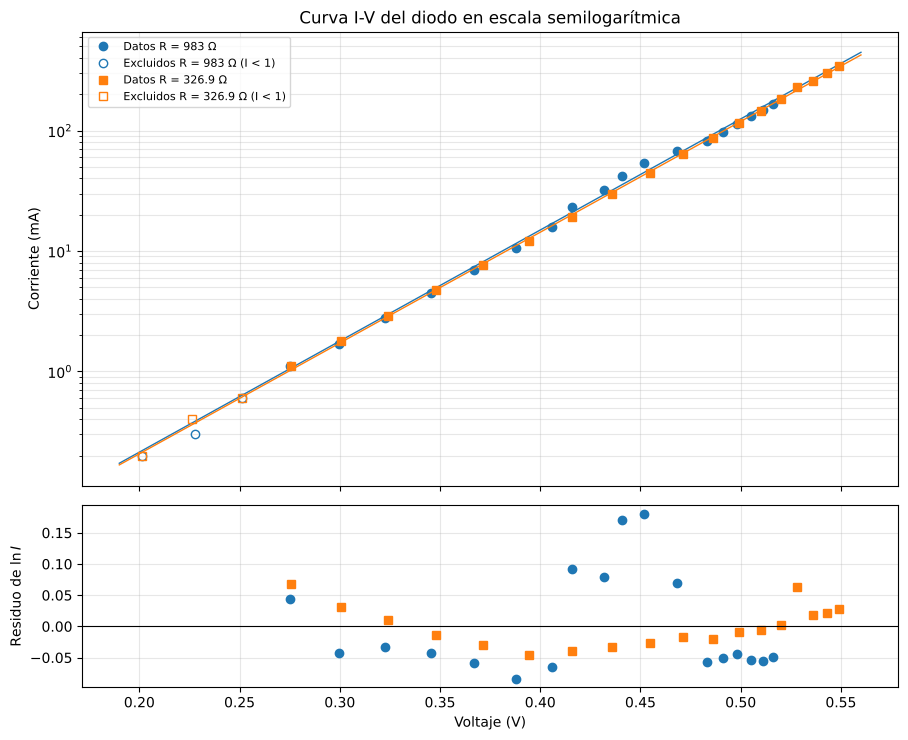

In [3]:
CORRIENTE_MINIMA = 1.0   # se excluyen lecturas limitadas por la resolución (0.1)

conjuntos = {
    "R = 983 Ω": (np.array(V1), np.array(I1)),
    "R = 326.9 Ω": (np.array(V2), np.array(I2)),
}


def ajuste_semilog(voltaje, corriente, corriente_minima=CORRIENTE_MINIMA):
    '''
    Regresión lineal de ln(I) frente a V para I >= corriente_minima.
    Devuelve n*V_T (V), I_S, sus incertidumbres y la máscara de puntos usados.
    '''
    usados = corriente >= corriente_minima
    coef, cov = np.polyfit(voltaje[usados], np.log(corriente[usados]), 1, cov=True)
    pendiente, ordenada = coef
    sig_pendiente, sig_ordenada = np.sqrt(np.diag(cov))
    nVt = 1.0 / pendiente
    sig_nVt = sig_pendiente / pendiente**2
    I_s = np.exp(ordenada)
    sig_I_s = I_s * sig_ordenada
    return nVt, sig_nVt, I_s, sig_I_s, usados


resultados_semilog = {}
for nombre, (V, I) in conjuntos.items():
    resultados_semilog[nombre] = ajuste_semilog(V, I)
    nVt, sig_nVt, I_s, sig_I_s, usados = resultados_semilog[nombre]
    print(f"{nombre}: {usados.sum()} puntos, n*V_T = ({1e3 * nVt:.2f} +/- {1e3 * sig_nVt:.2f}) mV, "
          f"I_S = ({I_s:.2e} +/- {sig_I_s:.1e}) mA")

# Ajuste conjunto: ambos conjuntos se midieron sobre el mismo diodo a la misma temperatura
V_todos = np.concatenate([conjuntos[k][0] for k in conjuntos])
I_todos = np.concatenate([conjuntos[k][1] for k in conjuntos])
nVt_c, sig_nVt_c, I_s_c, sig_I_s_c, usados_c = ajuste_semilog(V_todos, I_todos)
print(f"Ajuste conjunto: {usados_c.sum()} puntos, n*V_T = ({1e3 * nVt_c:.2f} +/- {1e3 * sig_nVt_c:.2f}) mV, "
      f"I_S = ({I_s_c:.2e} +/- {sig_I_s_c:.1e}) mA")

fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(9, 7.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1.2]})
V_linea = np.linspace(0.19, 0.56, 200)
for (nombre, (V, I)), marcador in zip(conjuntos.items(), ["o", "s"]):
    nVt, _, I_s, _, usados = resultados_semilog[nombre]
    linea, = ax.semilogy(V[usados], I[usados], marcador, label=f"Datos {nombre}")
    ax.semilogy(V[~usados], I[~usados], marcador, mfc="none", color=linea.get_color(),
                label=f"Excluidos {nombre} (I < {CORRIENTE_MINIMA:g})")
    ax.semilogy(V_linea, I_s * np.exp(V_linea / nVt), "-", color=linea.get_color(), lw=1)
    residuos = np.log(I[usados]) - (np.log(I_s) + V[usados] / nVt)
    ax_res.plot(V[usados], residuos, marcador, color=linea.get_color())
ax.set_ylabel("Corriente (mA)")
ax.set_title("Curva I-V del diodo en escala semilogarítmica")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
ax_res.axhline(0, color="black", lw=0.8)
ax_res.set_xlabel("Voltaje (V)")
ax_res.set_ylabel(r"Residuo de $\ln I$")
ax_res.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Figura 1.** Arriba: corriente frente a voltaje en escala logarítmica para los dos conjuntos de datos, con las rectas ajustadas (los símbolos vacíos son las lecturas excluidas del ajuste). Abajo: residuos del ajuste en $\ln I$.

### Factor de idealidad y constante de Boltzmann

A partir de $n V_T$ se calcula el factor de idealidad, tomando $k_B$ con su valor exacto del SI, y la constante de Boltzmann que resulta si se supone $n = 2$, el valor que corresponde a una corriente dominada por recombinación en la zona de carga espacial.

In [4]:
filas = list(resultados_semilog.items()) + [("Ajuste conjunto", (nVt_c, sig_nVt_c, None, None, None))]
print(f"{'Conjunto':<17}{'n (k_B exacta)':>18}{'k_B (n = 2) [1e-23 J/K]':>26}{'Diferencia con CODATA':>24}")
for nombre, (nVt, sig_nVt, *_ ) in filas:
    n_ideal = nVt * q / (k_codata * T)
    sig_n = sig_nVt * q / (k_codata * T)
    k_n2 = nVt * q / (2 * T)
    sig_k = sig_nVt * q / (2 * T)
    print(f"{nombre:<17}{n_ideal:>11.3f} +/- {sig_n:.3f}{k_n2 * 1e23:>15.4f} +/- {sig_k * 1e23:.4f}"
          f"{100 * (k_n2 - k_codata) / k_codata:>18.1f} %")

Conjunto             n (k_B exacta)   k_B (n = 2) [1e-23 J/K]   Diferencia con CODATA
R = 983 Ω              1.826 +/- 0.024         1.2607 +/- 0.0163              -8.7 %
R = 326.9 Ω            1.831 +/- 0.008         1.2638 +/- 0.0056              -8.5 %
Ajuste conjunto        1.832 +/- 0.012         1.2645 +/- 0.0083              -8.4 %


Para examinar si el factor de idealidad cambia a lo largo de la curva, se repite el ajuste por separado en el tramo de voltajes bajos ($V_D < 0.40$ V) y en el de voltajes altos ($V_D \geq 0.40$ V).

In [5]:
V_CORTE = 0.40   # V
print(f"{'Conjunto':<14}{'n (V < 0.40 V)':>18}{'n (V >= 0.40 V)':>20}")
for nombre, (V, I) in conjuntos.items():
    valores_n = []
    for tramo in (V < V_CORTE, V >= V_CORTE):
        nVt, sig_nVt, *_ = ajuste_semilog(V[tramo], I[tramo])
        valores_n.append((nVt * q / (k_codata * T), sig_nVt * q / (k_codata * T)))
    (n_bajo, s_bajo), (n_alto, s_alto) = valores_n
    print(f"{nombre:<14}{n_bajo:>11.3f} +/- {s_bajo:.3f}{n_alto:>13.3f} +/- {s_alto:.3f}")

Conjunto          n (V < 0.40 V)     n (V >= 0.40 V)
R = 983 Ω           1.907 +/- 0.024        1.948 +/- 0.064
R = 326.9 Ω         1.915 +/- 0.007        1.782 +/- 0.009


### Comparación con un ajuste no lineal en escala lineal

Un ajuste directo de la ecuación de Shockley a la corriente en escala lineal, sin pesos, minimiza la suma de los cuadrados de las diferencias en corriente. Como la corriente crece exponencialmente, esa suma está dominada por los pocos puntos de mayor corriente, y el resultado depende de la dispersión de esos puntos más que de la forma completa de la curva.

In [6]:
def ajuste_lineal(voltaje, corriente):
    '''Ajuste no lineal sin pesos de I = I_S (exp(V / nV_T) - 1) en escala lineal de corriente.'''
    def shockley(V, I_s, nVt):
        return I_s * (np.exp(V / nVt) - 1)
    popt, cov = curve_fit(shockley, voltaje, corriente, p0=[1e-3, 0.05], bounds=(0, np.inf))
    return popt, np.sqrt(np.diag(cov))


for nombre, (V, I) in conjuntos.items():
    (I_s_lin, nVt_lin), (_, sig_lin) = ajuste_lineal(V, I)
    # Sensibilidad de la corriente predicha a n*V_T en cada punto: en un ajuste sin
    # pesos, la información que aporta cada punto sobre el parámetro es proporcional
    # al cuadrado de esta derivada.
    derivada = I_s_lin * np.exp(V / nVt_lin) * V / nVt_lin**2
    peso_altos = np.sum(derivada[-5:]**2) / np.sum(derivada**2)
    print(f"{nombre}: n*V_T = ({1e3 * nVt_lin:.2f} +/- {1e3 * sig_lin:.2f}) mV en escala lineal "
          f"(escala logarítmica: {1e3 * resultados_semilog[nombre][0]:.2f} mV); "
          f"los 5 puntos de mayor corriente aportan el {100 * peso_altos:.0f} % de la información sobre n*V_T")

R = 983 Ω: n*V_T = (51.27 +/- 1.06) mV en escala lineal (escala logarítmica: 47.08 mV); los 5 puntos de mayor corriente aportan el 86 % de la información sobre n*V_T
R = 326.9 Ω: n*V_T = (45.94 +/- 0.44) mV en escala lineal (escala logarítmica: 47.20 mV); los 5 puntos de mayor corriente aportan el 89 % de la información sobre n*V_T


## Análisis y conclusiones

**Forma de la curva.** En escala semilogarítmica, los dos conjuntos de datos siguen la misma recta durante más de dos décadas de corriente (Figura 1), como predice la ecuación de Shockley para $V_D \gg n V_T$. Los ajustes dan $n V_T = 47.08 \pm 0.61$ mV y $47.20 \pm 0.21$ mV, compatibles entre sí. Es lo esperado: la característica $I$–$V$ del diodo no depende de la resistencia en serie con la que se polariza, que solo determina qué puntos de la curva se recorren al variar el voltaje de la fuente. Los residuos del primer conjunto muestran un exceso de corriente de entre el 10 % y el 20 % entre 0.41 V y 0.47 V que el segundo conjunto no reproduce en los mismos voltajes, por lo que se trata más probablemente de una fluctuación de las condiciones de medida que de una propiedad del diodo.

**Factor de idealidad.** Con $k_B$ fijada en su valor exacto del SI, el ajuste conjunto da $n = 1.832 \pm 0.012$. Un valor entre 1 y 2 indica que contribuyen a la corriente tanto la difusión de portadores ($n = 1$) como la recombinación en la zona de carga espacial ($n = 2$), cuyo peso relativo cambia con la polarización (Sze & Ng, 2007). Los ajustes por tramos son consistentes con esa interpretación: en el conjunto más preciso, el factor de idealidad pasa de unos 1.9 por debajo de 0.40 V a unos 1.8 por encima, es decir, la curva se vuelve algo más empinada al aumentar el voltaje, a medida que gana peso la corriente de difusión. Una resistencia en serie produciría el efecto contrario (una curva que se aplana a corrientes altas), de modo que en el rango medido no hay indicios de ella.

**Constante de Boltzmann.** Si se supone $n = 2$, el ajuste conjunto da $k_B = (1.2645 \pm 0.0083) \times 10^{-23}$ J/K, un 8.4 % por debajo del valor de CODATA, una diferencia diez veces mayor que la incertidumbre estadística. Esa diferencia no es un error de medida de $k_B$, sino la consecuencia de que el factor de idealidad real del diodo no es 2: a una sola temperatura, el experimento determina el producto $n\,k_B$ y no puede separar ambos factores. La incertidumbre de la temperatura del laboratorio contribuye poco: un error de 1 K en $T$ cambia $n$ o $k_B$ en un 0.3 %.

**Elección del ajuste.** El ajuste no lineal de la ecuación de Shockley en escala lineal de corriente da $n V_T = 51.27$ mV y $45.94$ mV para los dos conjuntos, es decir, $n = 1.99$ y $n = 1.78$, valores que difieren entre sí un 11 % y que, con $n = 2$, se traducirían en valores de $k_B$ igualmente dispares. La causa es el peso de los puntos: en ese ajuste, los cinco puntos de mayor corriente aportan casi el 90 % de la información sobre $n V_T$, de modo que el resultado depende de la dispersión de unas pocas lecturas y no de la forma completa de la curva. El ajuste en escala logarítmica pondera por igual todas las décadas y da resultados consistentes para ambos conjuntos.

## Conclusiones

1. Los dos conjuntos de datos, medidos con resistencias en serie distintas, describen la misma característica $I$–$V$, con $n V_T = 47.2 \pm 0.3$ mV en el ajuste conjunto.
2. Con $k_B$ exacta, el factor de idealidad del diodo es $n = 1.83 \pm 0.01$, propio de un régimen en el que coexisten la corriente de difusión y la de recombinación.
3. Suponiendo $n = 2$, se obtiene $k_B = (1.26 \pm 0.01) \times 10^{-23}$ J/K, un 8.4 % por debajo del valor de CODATA. Una determinación de $k_B$ independiente del factor de idealidad requiere medir la curva $I$–$V$ a varias temperaturas conocidas, de modo que $n$ y $k_B$ dejen de aparecer solo a través de su producto.
4. Para una ley exponencial, el ajuste en escala logarítmica es el adecuado: un ajuste sin pesos en escala lineal queda determinado por unos pocos puntos de corriente alta y produce diferencias entre conjuntos mayores que las incertidumbres estadísticas.

---

## Referencias

- Bevington, P. R., & Robinson, D. K. (2003). *Data reduction and error analysis for the physical sciences* (3rd ed.). McGraw-Hill.
- Sze, S. M., & Ng, K. K. (2007). *Physics of semiconductor devices* (3rd ed.). Wiley-Interscience.
- Tiesinga, E., Mohr, P. J., Newell, D. B., & Taylor, B. N. (2021). CODATA recommended values of the fundamental physical constants: 2018. *Reviews of Modern Physics*, 93(2), 025010. https://doi.org/10.1103/RevModPhys.93.025010